# Tu primer modelo propio: ¿este video es una receta?

Este notebook entrena y compara **tres clasificadores** que, leyendo solo el **título y la descripción** de un video,
deciden si es una receta de cocina. En la app sirven para rechazar al instante los videos que claramente no son recetas,
**antes** de descargarlos y de pagar el análisis con Claude.

Lo que vas a ver:

1. **Datos con etiquetas débiles** — cómo conseguir ~1000 ejemplos etiquetados gratis.
2. **División honesta** — por qué los canales de prueba no pueden aparecer en entrenamiento.
3. **Modelo A: TF-IDF + regresión logística** — machine learning clásico, y qué palabras aprendió.
4. **Modelo B: embeddings + regresión logística** — *transfer learning* con un modelo ya entrenado.
5. **Modelo C: ajuste fino (fine-tuning)** — *deep learning*: reentrenar una red transformer completa con PyTorch.
6. **Comparación**, curvas ROC y errores.
7. **Ruido en las etiquetas** — usar el propio modelo para encontrar ejemplos mal etiquetados.
8. **El umbral de producción** — cómo decidir cuándo rechazar sin bloquear recetas reales.

Todo el código de entrenamiento vive en `scripts/train_classifier.py`; aquí lo usamos paso a paso.

In [1]:
import sys, json
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent))          # carpeta backend/
sys.path.insert(0, str(Path.cwd().parent / "scripts"))

import numpy as np
import matplotlib.pyplot as plt
from collections import Counter
import train_classifier as tc

plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
COLORS = {"receta": "#C4512B", "comida_no_receta": "#E0A030", "no_comida": "#5B7A99"}

## 1. Datos con etiquetas débiles

Etiquetar 1000 videos a mano llevaría horas. En su lugar usamos **etiquetas débiles** (*weak labels*):
la búsqueda que trajo cada video decide su etiqueta.

- Lo que sale al buscar «receta de pan casero» → **receta (1)**
- Lo que sale al buscar «resumen de fútbol» → **no receta (0)**
- Lo que sale al buscar «reseña de restaurante», «mukbang»… → **no receta (0)**: son los **negativos difíciles**, videos de comida que no son recetas.
  Sin ellos el modelo aprendería el atajo «habla de comida = receta».

Las etiquetas débiles tienen ruido (algún video de la búsqueda «receta fácil» puede no serlo). Lo medimos en la sección 7.

In [2]:
ds = tc.load_dataset()
kinds = Counter(i["kind"] for i in ds.items)
print(f"{len(ds.texts)} videos")
for k, n in kinds.most_common():
    print(f"  {k:18} {n}")

for kind in ["receta", "comida_no_receta", "no_comida"]:
    print(f"\n— Ejemplos de «{kind}»:")
    for item in [i for i in ds.items if i["kind"] == kind][:3]:
        print("  ·", item["title"][:90])

1335 videos
  receta             592
  no_comida          500
  comida_no_receta   243

— Ejemplos de «receta»:
  · SI Tienes MANZANAS Y HUEVOS prepara esta receta fácil y rápida Sin Horno!!?
  · Tienes papas? Te enseño una receta fácil y Deliciosa!! Sin freír, sin horno!!! En 5 minuto
  · My Grandma Made This Cake and No One Knew It Was Healthy. Oatmeal Cake with Dates

— Ejemplos de «comida_no_receta»:
  · EL PEOR RESTAURANTE EN MÉXICO VS EL MEJOR RESTAURANTE
  · I went to 1 star restaurants.
  · Eating at a 3 Michelin Star Restaurant

— Ejemplos de «no_comida»:
  · ¿SOBREVIVIREMOS A ÚLTIMO TABLERO? | INVOKYR Gameplay Español
  · ZELDA OCARINA OF TIME REMAKE Juego Completo en Español LATINO | Guía 100% Gameplay
  · ZACH CREGGER'S: RESIDENT EVIL | THE VIDEO GAME | Gameplay English


Así ve el texto el modelo: título + inicio de la descripción, sin enlaces. **No ve el nombre del canal** a propósito:
aprendería atajos («canal de cocina») que no sirven para Instagram, TikTok ni canales nuevos.

In [3]:
print(ds.texts[0][:400])

SI Tienes MANZANAS Y HUEVOS prepara esta receta fácil y rápida Sin Horno!!? SI Tienes MANZANAS Y HUEVOS prepara esta receta fácil y rápida Sin Horno!!?


## 2. División honesta: entrenamiento, validación y prueba

- **Entrenamiento**: con lo que aprende el modelo.
- **Validación**: para elegir el modelo y el umbral.
- **Prueba**: solo para medir al final. Nunca se usa para decidir nada.

Un canal suele subir videos muy parecidos. Si un canal aparece en entrenamiento y en prueba, el modelo puede «acertar» reconociendo
el estilo del canal en vez de entender si es una receta. Por eso dividimos **por canal** (`GroupShuffleSplit`).

In [4]:
train, val, test = tc.split(ds)
for name, part in [("entrenamiento", train), ("validación", val), ("prueba", test)]:
    print(f"{name:14} {len(part.texts):4} videos · {part.labels.mean():.0%} recetas · {len(set(part.groups))} canales")
print("canales compartidos entre entrenamiento y prueba:", len(set(train.groups) & set(test.groups)))

entrenamiento   812 videos · 40% recetas · 500 canales
validación      240 videos · 55% recetas · 116 canales
prueba          283 videos · 49% recetas · 154 canales
canales compartidos entre entrenamiento y prueba: 0


## 3. Modelo A — TF-IDF + regresión logística (machine learning clásico)

**TF-IDF** convierte cada texto en un vector con una posición por palabra (y por par de palabras). El valor es alto si la palabra
aparece en ese texto pero es rara en el resto. La **regresión logística** aprende un peso por posición: positivo si empuja hacia
«receta», negativo si empuja hacia «no receta». Es rápido, barato e **interpretable**: podemos leer qué aprendió.

In [5]:
tfidf = tc.train_tfidf(train)
p_val_A, p_test_A = tfidf.predict_proba(val.texts)[:, 1], tfidf.predict_proba(test.texts)[:, 1]
thr_A = tc.choose_threshold(val.labels, p_val_A)
tc.metrics(test.labels, p_test_A, thr_A)

{'exactitud': 0.9859,
 'precision': 0.9926,
 'recall': 0.9783,
 'f1': 0.9854,
 'auc': 0.9993,
 'umbral_rechazo': 0.138,
 'recetas_bloqueadas': 0,
 'recetas_total': 138,
 'no_recetas_detectadas': 70,
 'no_recetas_total': 145}

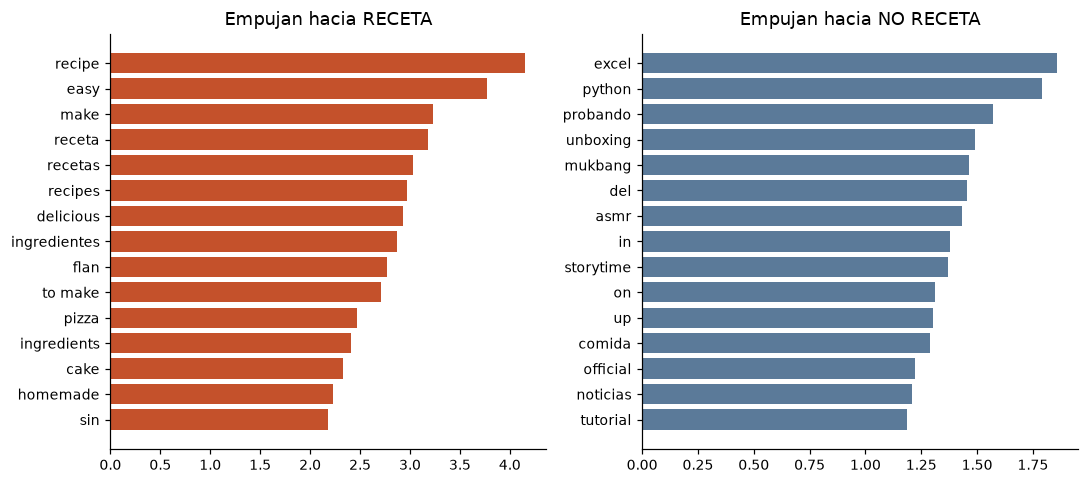

In [6]:
vec, lr = tfidf.named_steps["tfidfvectorizer"], tfidf.named_steps["logisticregression"]
words, weights = np.array(vec.get_feature_names_out()), lr.coef_[0]
order = np.argsort(weights)
fig, axes = plt.subplots(1, 2, figsize=(10, 4.5))
for ax, idx, color, title in [(axes[0], order[-15:], COLORS["receta"], "Empujan hacia RECETA"),
                              (axes[1], order[:15][::-1], COLORS["no_comida"], "Empujan hacia NO RECETA")]:
    ax.barh(words[idx], np.abs(weights[idx]), color=color)
    ax.set_title(title); ax.tick_params(labelsize=9)
plt.tight_layout(); plt.show()

**Un atajo que encontramos así:** en la primera versión, la señal más fuerte de «no receta» era el número **«2026»**.
No tiene nada que ver con cocinar: las búsquedas de noticias, gameplays y restaurantes traían videos recientes que mencionan el año,
y las de recetas no. El modelo aprendió una correlación del *dataset*, no de la tarea, y habría penalizado cualquier receta que dijera
«receta navideña 2026». Lo corregimos haciendo que TF-IDF solo use palabras con letras (`token_pattern`). El rendimiento no bajó.

Mirar qué aprendió el modelo, y no solo su exactitud, es la mejor forma de detectar estos atajos.

## 4. Modelo B — embeddings + regresión logística (transfer learning)

En vez de contar palabras, usamos **e5-small**, una red neuronal que ya fue entrenada con millones de textos en muchos idiomas
(la misma de la búsqueda de la fase 3). Convierte cada texto en un vector de 384 números que captura su **significado**:
«receta de pan» y «cómo hornear pan casero» quedan cerca aunque no compartan palabras.

Encima ponemos una regresión logística. Es *transfer learning*: reutilizamos lo que la red ya sabe y solo entrenamos la última capa.

In [7]:
E_train, E_val, E_test = tc.embed(train.texts), tc.embed(val.texts), tc.embed(test.texts)
emb_lr = tc.train_embeddings_lr(train, E_train)
p_val_B, p_test_B = emb_lr.predict_proba(E_val)[:, 1], emb_lr.predict_proba(E_test)[:, 1]
thr_B = tc.choose_threshold(val.labels, p_val_B)
tc.metrics(test.labels, p_test_B, thr_B)

W1111 21:00:57.090000 40313 .venv/lib/python3.11/site-packages/torch/distributed/elastic/multiprocessing/redirects.py:35] NOTE: Redirects are currently not supported in MacOs.


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

{'exactitud': 0.9823,
 'precision': 0.9854,
 'recall': 0.9783,
 'f1': 0.9818,
 'auc': 0.9979,
 'umbral_rechazo': 0.0806,
 'recetas_bloqueadas': 0,
 'recetas_total': 138,
 'no_recetas_detectadas': 34,
 'no_recetas_total': 145}

**¿Cómo ve la red los videos?** Reducimos los vectores de 384 dimensiones a 2 con PCA para dibujarlos. Cada punto es un video.
Si los colores forman grupos separados, la red ya «entiende» la diferencia antes de entrenar nada.

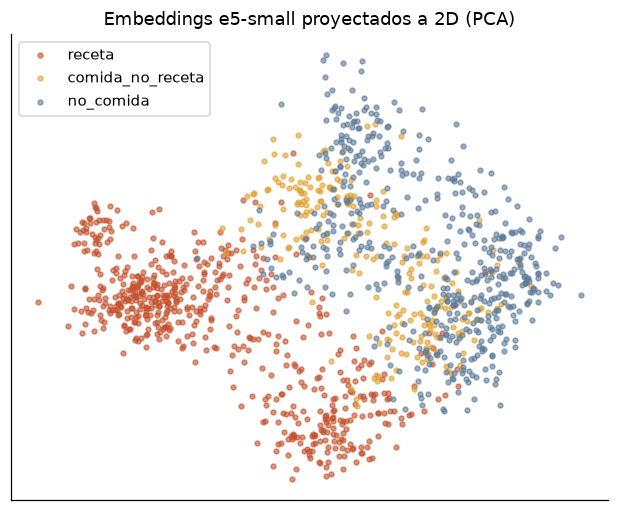

In [8]:
from sklearn.decomposition import PCA
E_all = np.vstack([E_train, E_val, E_test])
kinds_all = [i["kind"] for part in (train, val, test) for i in part.items]
xy = PCA(n_components=2, random_state=0).fit_transform(E_all)
plt.figure(figsize=(7, 5.5))
for kind, color in COLORS.items():
    m = np.array([k == kind for k in kinds_all])
    plt.scatter(xy[m, 0], xy[m, 1], s=10, alpha=0.6, c=color, label=kind)
plt.legend(); plt.title("Embeddings e5-small proyectados a 2D (PCA)"); plt.xticks([]); plt.yticks([]); plt.show()

## 5. Modelo C — ajuste fino de la red completa (deep learning)

Ahora **reentrenamos toda la red e5-small** (118 millones de parámetros) junto con una capa de clasificación nueva.
Con PyTorch, en la GPU del Mac:

- Cada **época** recorre todos los ejemplos de entrenamiento en lotes de 16.
- Para cada lote, la red predice, se mide el error (*binary cross-entropy*) y el optimizador **AdamW** ajusta todos los pesos un poco
  en la dirección que reduce el error (*backpropagation*).
- Usamos una tasa de aprendizaje pequeña (3e-5) para no «olvidar» lo que la red ya sabía.

Tarda unos minutos.

In [9]:
ft = tc.train_finetuned(train, val, epochs=3)
p_val_C, p_test_C = ft["predict"](val.texts), ft["predict"](test.texts)
thr_C = tc.choose_threshold(val.labels, p_val_C)
tc.metrics(test.labels, p_test_C, thr_C)

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

  época 1: pérdida 0.4733 · exactitud validación 0.929


  época 2: pérdida 0.1490 · exactitud validación 0.958


  época 3: pérdida 0.1340 · exactitud validación 0.975


{'exactitud': 0.9894,
 'precision': 0.9787,
 'recall': 1.0,
 'f1': 0.9892,
 'auc': 0.9998,
 'umbral_rechazo': 0.0307,
 'recetas_bloqueadas': 0,
 'recetas_total': 138,
 'no_recetas_detectadas': 0,
 'no_recetas_total': 145}

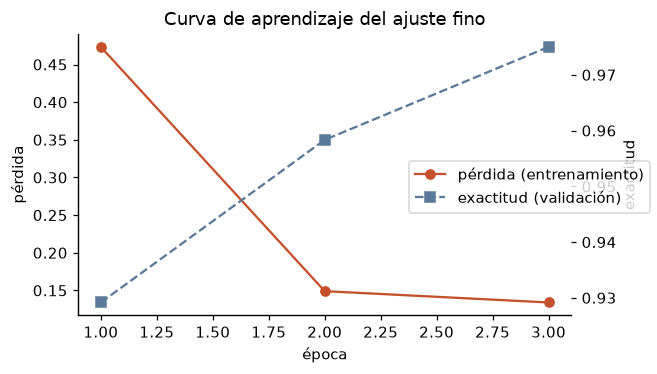

In [10]:
h = ft["history"]
fig, ax1 = plt.subplots(figsize=(6, 3.5))
ax1.plot([x["epoch"] for x in h], [x["train_loss"] for x in h], "o-", color=COLORS["receta"], label="pérdida (entrenamiento)")
ax1.set_xlabel("época"); ax1.set_ylabel("pérdida")
ax2 = ax1.twinx(); ax2.plot([x["epoch"] for x in h], [x["val_accuracy"] for x in h], "s--", color=COLORS["no_comida"], label="exactitud (validación)")
ax2.set_ylabel("exactitud"); ax1.set_title("Curva de aprendizaje del ajuste fino"); fig.legend(loc="center right"); plt.tight_layout(); plt.show()

## 6. Comparación

- **Exactitud**: % de aciertos.  **Precisión**: de lo que el modelo llama receta, cuánto lo es.  **Recall**: de las recetas reales, cuántas detecta.
- **F1**: equilibrio entre precisión y recall.  **AUC**: qué tan bien ordena (1 = perfecto, 0,5 = al azar).
- **Recetas bloqueadas**: con el umbral de producción, recetas reales que se rechazarían por error. **Tiene que ser 0.**

In [11]:
import pandas as pd
rows = {}
for name, pv, pt, thr in [("A · TF-IDF", p_val_A, p_test_A, thr_A), ("B · embeddings", p_val_B, p_test_B, thr_B), ("C · ajuste fino", p_val_C, p_test_C, thr_C)]:
    m = tc.metrics(test.labels, pt, thr)
    mv = tc.metrics(val.labels, pv, thr)
    m["f1_validacion"] = mv["f1"]
    m["filtro_validacion"] = round(mv["no_recetas_detectadas"] / max(1, mv["no_recetas_total"]), 3)
    rows[name] = m
pd.DataFrame(rows).T[["exactitud", "f1", "auc", "f1_validacion", "filtro_validacion", "umbral_rechazo", "recetas_bloqueadas", "no_recetas_detectadas", "no_recetas_total"]]

,exactitud,f1,auc,f1_validacion,filtro_validacion,umbral_rechazo,recetas_bloqueadas,no_recetas_detectadas,no_recetas_total
A · TF-IDF,0.9859,0.9854,0.9993,0.9609,0.385,0.1380,0.0,70.0,145.0
B · embeddings,0.9823,0.9818,0.9979,0.9380,0.128,0.0806,0.0,34.0,145.0
C · ajuste fino,0.9894,0.9892,0.9998,0.9767,0.000,0.0307,0.0,0.0,145.0


### La lección: elige la métrica según el uso real

Si miramos solo el **F1**, gana el ajuste fino (la red neuronal). Pero en la app el modelo no se usa en la frontera del 50 %:
se usa como **filtro** que solo rechaza cuando está *muy* seguro. Con el umbral que no bloquea ninguna receta,
la red ajustada casi nunca da probabilidades tan bajas y **no rechazaría prácticamente nada** (columna `filtro_validacion`).

El modelo clásico TF-IDF, que entrena en una fracción de segundo y ocupa 200 KB, es el que más videos inútiles filtra sin bloquear recetas.
Por eso es el que va a producción. Más complejo no siempre es mejor: depende de **para qué** se usa el modelo.

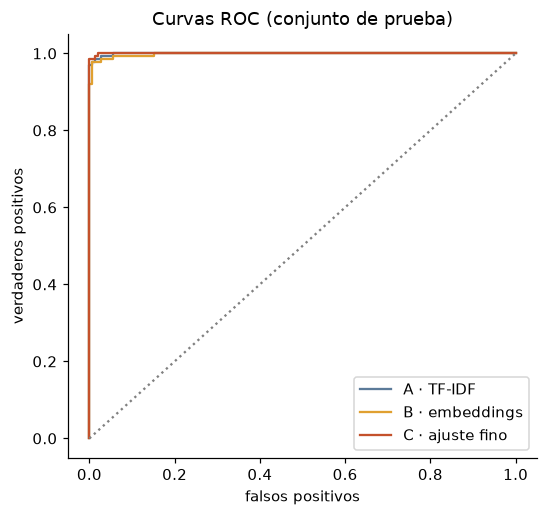

In [12]:
from sklearn.metrics import roc_curve
plt.figure(figsize=(5.5, 5))
for name, p, color in [("A · TF-IDF", p_test_A, COLORS["no_comida"]), ("B · embeddings", p_test_B, COLORS["comida_no_receta"]), ("C · ajuste fino", p_test_C, COLORS["receta"])]:
    fpr, tpr, _ = roc_curve(test.labels, p)
    plt.plot(fpr, tpr, label=name, color=color)
plt.plot([0, 1], [0, 1], ":", color="gray")
plt.xlabel("falsos positivos"); plt.ylabel("verdaderos positivos"); plt.title("Curvas ROC (conjunto de prueba)"); plt.legend(); plt.show()

### ¿En qué se equivoca cada modelo?

Mirar los errores enseña más que cualquier métrica: a veces el «error» es del modelo y a veces de la etiqueta.

In [13]:
for name, p in [("A · TF-IDF", p_test_A), ("B · embeddings", p_test_B), ("C · ajuste fino", p_test_C)]:
    wrong = np.where((p >= 0.5) != test.labels)[0]
    print(f"\n{name}: {len(wrong)} errores de {len(test.labels)}")
    for i in wrong[:6]:
        print(f"  [etiqueta {test.labels[i]} · prob. receta {p[i]:.2f} · {test.items[i]['kind']}] {test.items[i]['title'][:80]}")


A · TF-IDF: 4 errores de 283
  [etiqueta 1 · prob. receta 0.32 · receta] Korean BBQ at Home 🥩🥬
  [etiqueta 1 · prob. receta 0.41 · receta] FLUFFY, EASY AND ECONOMICAL 5-CUP CAKE
  [etiqueta 1 · prob. receta 0.46 · receta] El Mejor Lomo Saltado | RECETA PERUANA | Sazón y Corazón
  [etiqueta 0 · prob. receta 0.52 · no_comida] [ EXCEL ] como Hacer un  SISTEMA de INVENTARIO  de entradas salidas y control  d

B · embeddings: 5 errores de 283
  [etiqueta 1 · prob. receta 0.28 · receta] Korean BBQ at Home 🥩🥬
  [etiqueta 1 · prob. receta 0.43 · receta] Give me 6 minutes, I'll change how you make pizza FOREVER
  [etiqueta 1 · prob. receta 0.47 · receta] This is How I Get PERFECT Pizza Dough EVERY Time
  [etiqueta 0 · prob. receta 0.51 · comida_no_receta] ASMR MUKBANG | Spicy Seafood Boil 🐙🦑 Mushrooms, Octopus, Squid, Scallop recipe E
  [etiqueta 0 · prob. receta 0.69 · comida_no_receta] ¡Tour de Comida Prohibida en El Cairo! Comida EXÓTICA de Egipto

C · ajuste fino: 3 errores de 283
  [etique

## 7. Ruido en las etiquetas: el modelo como revisor

Las etiquetas débiles tienen errores. Una técnica (*confident learning*) es entrenar con validación cruzada, de forma que cada video
reciba una predicción de un modelo que **no lo vio**, y revisar los casos donde el modelo está muy seguro de lo contrario de la etiqueta.
Los que de verdad estaban mal se corrigen en `data/classifier/label_fixes.json` y se reentrena.

In [14]:
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import GroupKFold, cross_val_predict
E_ds = tc.embed(ds.texts)
oof = cross_val_predict(LogisticRegression(C=2.0, class_weight="balanced", max_iter=2000), E_ds, ds.labels,
                        groups=ds.groups, cv=GroupKFold(n_splits=5), method="predict_proba")[:, 1]
disagree = np.argsort(-np.abs(oof - ds.labels))[:15]
for i in disagree:
    it = ds.items[i]
    fixed = " (ya corregida)" if it.get("fixed") else ""
    print(f"etiqueta {ds.labels[i]} · modelo {oof[i]:.2f} · búsqueda «{it['query']}»{fixed}\n    {it['title'][:95]}")

etiqueta 1 · modelo 0.12 · búsqueda «asado a la parrilla cómo hacer»
    SACRED FIRE II: Locos X el Asado Masterclass
etiqueta 1 · modelo 0.14 · búsqueda «desayuno saludable receta»
    Episodio #1425 Desayuno Saludable Para Niños
etiqueta 1 · modelo 0.20 · búsqueda «how to make pizza dough»
    New York-style pizza at home, v2.0
etiqueta 1 · modelo 0.23 · búsqueda «asado a la parrilla cómo hacer»
    Korean BBQ at Home 🥩🥬
etiqueta 1 · modelo 0.25 · búsqueda «receta shorts cocina»
    WE MADE EVERY VIRAL TIKTOK RECIPE!
etiqueta 1 · modelo 0.26 · búsqueda «asado a la parrilla cómo hacer»
    Cabrito | Locos x el Asado México | Food Network Latonomérica
etiqueta 0 · modelo 0.71 · búsqueda «probando comida rara»
    ¡Tour de Comida Prohibida en El Cairo! Comida EXÓTICA de Egipto
etiqueta 0 · modelo 0.67 · búsqueda «mukbang»
    EATING FOOD||SPICY FISH PASTE WITH PRAWN AND FISH CURRY
etiqueta 1 · modelo 0.34 · búsqueda «salsa casera receta»
    HOMEMADE RED SAUCE FOR SALE OR HOME, Red Sauc

## 8. El umbral de producción

En la app el modelo **solo rechaza** cuando está muy seguro: si la probabilidad de receta es menor que el umbral.
Elegimos el umbral en **validación** como la mitad de la puntuación de la receta peor puntuada: así ninguna receta de validación se
habría bloqueado, con margen para videos nuevos. Todo lo que queda por encima se analiza normalmente con Claude.

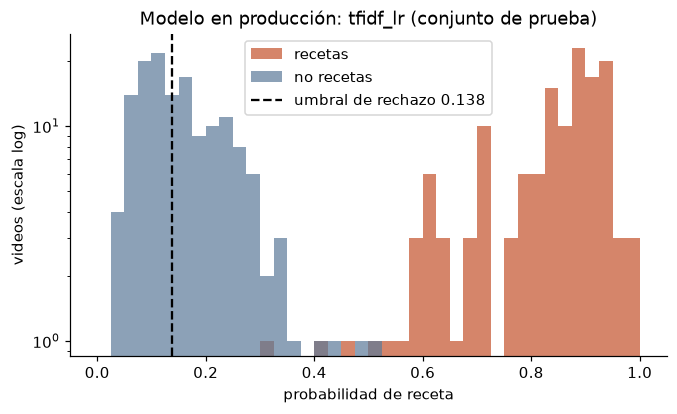

In [15]:
best = json.loads((tc.MODEL_DIR / "config.json").read_text()) if (tc.MODEL_DIR / "config.json").exists() else None
p_best = {"tfidf_lr": p_test_A, "embeddings_lr": p_test_B, "finetuned": p_test_C}[best["type"]] if best else p_test_B
thr = best["reject_below"] if best else thr_B
plt.figure(figsize=(7, 3.8))
bins = np.linspace(0, 1, 41)
plt.hist(p_best[test.labels == 1], bins=bins, alpha=0.7, color=COLORS["receta"], label="recetas")
plt.hist(p_best[test.labels == 0], bins=bins, alpha=0.7, color=COLORS["no_comida"], label="no recetas")
plt.axvline(thr, color="black", ls="--", label=f"umbral de rechazo {thr:.3f}")
plt.yscale("log"); plt.xlabel("probabilidad de receta"); plt.ylabel("videos (escala log)")
plt.title(f"Modelo en producción: {best['type'] if best else '—'} (conjunto de prueba)"); plt.legend(); plt.show()

## Conclusión

`scripts/train_classifier.py` hace todo esto de forma reproducible y guarda en `models/recipe_classifier/` el modelo elegido:
el de mejor F1 en **validación**, y ante empate el más simple (más rápido y barato de servir).
Su informe completo está en `models/recipe_classifier/report.json`.

**Siguientes pasos para mejorarlo:**
- Añadir ejemplos reales de Instagram y TikTok (sus descripciones son distintas a las de YouTube).
- Usar los videos que la app rechaza y que el usuario manda «analizar de todos modos»: son errores del modelo, los mejores ejemplos para reentrenar.
- Revisar más etiquetas con la sección 7 y volver a entrenar.